# Анализ системы метрик приложения

## Контекст и цель исследования

Procrastinate Pro+ — приложение с развлекательным контентом: видео, подкастами и блогами. В начале лета в продукт добавили спортивный контент и скорректировали маркетинговую стратегию. После изменений интерес к приложению вырос, однако выручка начала стагнировать.

**Цель исследования:** проанализировать динамику продуктовых метрик и юнит-экономику привлечения, выявить причины стагнации выручки и оценить эффективность рекламных каналов. Целевой срок окупаемости привлечения — 28 дней.

**Задачи анализа:**
- оценить активность и вовлечённость пользователей;
- рассчитать CAC, LTV и ROI по когортам;
- сравнить рекламные каналы по удержанию, конверсии и окупаемости;
- оценить сроки окупаемости и сформулировать рекомендации по маркетинговым расходам.

### Данные

Исследование основано на трёх датасетах:

1. `ppro_visits.csv` — посещения приложения пользователями, зарегистрировавшимися с 1 апреля по 30 ноября 2024 года:
   - `user_id` — идентификатор пользователя;
   - `region` — страна пользователя;
   - `device` — категория устройства;
   - `channel` — рекламный источник;
   - `session_start` — начало сессии;
   - `session_end` — окончание сессии.
2. `ppro_orders.csv` — покупки:
   - `user_id` — идентификатор пользователя;
   - `event_dt` — время покупки;
   - `revenue` — выручка.
3. `ppro_costs.csv` — маркетинговые расходы:
   - `dt` — дата;
   - `channel` — рекламный источник;
   - `costs` — расходы на источник за день.

### Структура исследования

1. Загрузка и предобработка данных.
2. Подготовка профилей пользователей и когорт.
3. Динамика продуктовых и финансовых метрик.
4. Анализ каналов привлечения.
5. Окупаемость маркетинговых вложений.
6. Выводы и рекомендации.


## Загрузка и предобработка данных

**Импорт библиотек, загрузка данных и настройка стиля визуализации**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors
df = pd.read_csv('https://code.s3.yandex.net/datasets/ppro_visits.csv')
df_orders = pd.read_csv('https://code.s3.yandex.net/datasets/ppro_orders.csv')
df_costs = pd.read_csv('https://code.s3.yandex.net/datasets/ppro_costs.csv')
sns.set_theme(style='whitegrid')
PALETTE = 'viridis'

**Первые строки датафреймов и общая информация о каждом**

In [2]:
df.head()

,user_id,region,device,channel,session_start,session_end
0,631105188566,India,desktop,MediaTornado,2024-04-01 03:48:00,2024-04-01 04:19:00
1,892885906464,India,tv,RocketSuperAds,2024-04-01 00:47:00,2024-04-01 01:14:00
2,517003690029,India,mobile,MediaTornado,2024-04-01 17:31:00,2024-04-01 17:53:00
3,185156659289,India,mobile,MediaTornado,2024-04-01 14:36:00,2024-04-01 14:51:00
4,409503040345,India,mobile,RocketSuperAds,2024-04-01 08:25:00,2024-04-01 08:45:00


In [3]:
df_orders.head()

,user_id,event_dt,revenue
0,771951256319,2024-04-01 05:56:26,2.99
1,829942381059,2024-04-01 14:55:02,2.99
2,727879856738,2024-04-01 22:15:09,14.99
3,481270888930,2024-04-01 06:05:14,2.99
4,844695029762,2024-04-01 01:19:52,2.99


In [4]:
df_costs.head()

,dt,channel,costs
0,2024-04-01,FaceBoom,124.938874
1,2024-04-02,FaceBoom,88.147779
2,2024-04-03,FaceBoom,120.779457
3,2024-04-04,FaceBoom,98.981253
4,2024-04-05,FaceBoom,109.044760


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 161865 entries, 0 to 161864
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   user_id        161865 non-null  int64 
 1   region         161865 non-null  object
 2   device         161865 non-null  object
 3   channel        161865 non-null  object
 4   session_start  161865 non-null  object
 5   session_end    161865 non-null  object
dtypes: int64(1), object(5)
memory usage: 7.4+ MB


In [6]:
df_orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33893 entries, 0 to 33892
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   user_id   33893 non-null  int64  
 1   event_dt  33893 non-null  object 
 2   revenue   33893 non-null  float64
dtypes: float64(1), int64(1), object(1)
memory usage: 794.5+ KB


In [7]:
df_costs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 976 entries, 0 to 975
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   dt       976 non-null    object 
 1   channel  976 non-null    object 
 2   costs    976 non-null    float64
dtypes: float64(1), object(2)
memory usage: 23.0+ KB


**Проверка наличия дубликатов**

In [8]:
print('Дубликаты в основном датафрейме (df):', df.duplicated().sum())
print('Дубликаты в датафрейме с заказами (df_orders):', df_orders.duplicated().sum())
print('Дубликаты в датафрейме с затратами на маркетинг (df_costs):', df_costs.duplicated().sum())

Дубликаты в основном датафрейме (df): 0
Дубликаты в датафрейме с заказами (df_orders): 0
Дубликаты в датафрейме с затратами на маркетинг (df_costs): 0


**Проверка наличия пропусков**

In [9]:
print('Всего пропусков в основном датафрейме (df):', df.isna().sum().sum())
print('Всего пропусков в датафрейме с заказами (df_orders):', df_orders.isna().sum().sum())
print('Всего пропусков в датафрейме с затратами на маркетинг (df_costs):', df_costs.isna().sum().sum())

Всего пропусков в основном датафрейме (df): 0
Всего пропусков в датафрейме с заказами (df_orders): 0
Всего пропусков в датафрейме с затратами на маркетинг (df_costs): 0


**Логическая проверка данных**

In [10]:
print('Сессий, где session_end раньше session_start:', (df['session_end'] < df['session_start']).sum())
print('Отрицательных значений revenue:', (df_orders['revenue'] < 0).sum())
print('Отрицательных значений costs:', (df_costs['costs'] < 0).sum())

Сессий, где session_end раньше session_start: 0
Отрицательных значений revenue: 0
Отрицательных значений costs: 0


**Проверка уникальных значений**

In [11]:
print('Уникальные значения region:', df['region'].unique())
print('Уникальные значения device:', df['device'].unique())
print('Уникальные значения channel:', df['channel'].unique())

Уникальные значения region: ['India']
Уникальные значения device: ['desktop' 'tv' 'mobile']
Уникальные значения channel: ['MediaTornado' 'RocketSuperAds' 'FaceBoom' 'TipTop']


**Замена типов данных на корректные**

In [12]:
df['session_start'] = pd.to_datetime(df['session_start'])
df['session_end'] = pd.to_datetime(df['session_end'])
df_orders['event_dt'] = pd.to_datetime(df_orders['event_dt'])
df_costs['dt'] = pd.to_datetime(df_costs['dt'])

<span style="font-size: 15px;">Исходный датасет достаточно чистый, кроме замены типа данных для дат, не понадобилось вносить никакие изменения. Дубликаты, пропуски и опечатки в текстовых значениях отсутствуют. </span>

## Подготовка данных к когортному анализу

**Создание таблицы с датой и каналом привлечения для каждого пользователя, а также рассчетом  CAC**

In [13]:
profiles = (
    df.sort_values('session_start')
    .groupby('user_id')
    .first()
    .reset_index()
)

profiles = profiles[['user_id', 'session_start', 'channel']]
profiles = profiles.rename(columns={
    'session_start': 'first_dt',
    'channel': 'first_channel'
})

profiles['first_dt'] = profiles['first_dt'].dt.date

new_users = (
    profiles
    .groupby(['first_dt', 'first_channel'])['user_id']
    .nunique()
    .reset_index(name='n_users')
)

df_costs['dt'] = df_costs['dt'].dt.date

profiles = profiles.merge(
    df_costs,
    left_on=['first_dt', 'first_channel'],
    right_on=['dt', 'channel'],
    how='left'
)
profiles = profiles.merge(
    new_users,
    on=['first_dt', 'first_channel'],
    how='left'
)

profiles = profiles[
    pd.to_datetime(profiles['first_dt']) < pd.Timestamp('2024-11-01')
].copy()

profiles['cac'] = profiles['costs'] / profiles['n_users']

profiles = profiles[['user_id', 'first_dt', 'first_channel', 'cac']]

profiles.head()

,user_id,first_dt,first_channel,cac
0,26034876,2024-05-29,FaceBoom,0.953250
1,69890364,2024-06-28,RocketSuperAds,0.604917
2,75610104,2024-06-09,FaceBoom,1.196159
3,76692397,2024-10-21,FaceBoom,1.147967
4,80224421,2024-06-21,FaceBoom,1.208981


**Присоединение данных о дате и источнике привлечения каждого пользователя к датафреймам df и df_orders**

In [14]:
df = df.merge(
    profiles[['user_id', 'first_dt', 'first_channel']],
    on='user_id',
    how='left'
)

df_orders = df_orders.merge(
    profiles[['user_id', 'first_dt', 'first_channel']],
    on='user_id',
    how='left'
)
display(df.head())
display(df_orders.head())

,user_id,region,device,channel,session_start,session_end,first_dt,first_channel
0,631105188566,India,desktop,MediaTornado,2024-04-01 03:48:00,2024-04-01 04:19:00,2024-04-01,MediaTornado
1,892885906464,India,tv,RocketSuperAds,2024-04-01 00:47:00,2024-04-01 01:14:00,2024-04-01,RocketSuperAds
2,517003690029,India,mobile,MediaTornado,2024-04-01 17:31:00,2024-04-01 17:53:00,2024-04-01,MediaTornado
3,185156659289,India,mobile,MediaTornado,2024-04-01 14:36:00,2024-04-01 14:51:00,2024-04-01,MediaTornado
4,409503040345,India,mobile,RocketSuperAds,2024-04-01 08:25:00,2024-04-01 08:45:00,2024-04-01,RocketSuperAds


,user_id,event_dt,revenue,first_dt,first_channel
0,771951256319,2024-04-01 05:56:26,2.99,2024-04-01,FaceBoom
1,829942381059,2024-04-01 14:55:02,2.99,2024-04-01,FaceBoom
2,727879856738,2024-04-01 22:15:09,14.99,2024-04-01,FaceBoom
3,481270888930,2024-04-01 06:05:14,2.99,2024-04-01,TipTop
4,844695029762,2024-04-01 01:19:52,2.99,2024-04-01,FaceBoom


**Расчет дневного лайфтайма для каждого события и покупки, а также присоединение соответствующего столбца к датасетам**

In [15]:
df['lifetime'] = (
    df['session_start'].dt.date - df['first_dt']
).apply(lambda x: x.days)
df_orders['lifetime'] = (
    df_orders['event_dt'].dt.date - df_orders['first_dt']
).apply(lambda x: x.days)
display(df.head())

display(df_orders.head())

,user_id,region,device,channel,session_start,session_end,first_dt,first_channel,lifetime
0,631105188566,India,desktop,MediaTornado,2024-04-01 03:48:00,2024-04-01 04:19:00,2024-04-01,MediaTornado,0.0
1,892885906464,India,tv,RocketSuperAds,2024-04-01 00:47:00,2024-04-01 01:14:00,2024-04-01,RocketSuperAds,0.0
2,517003690029,India,mobile,MediaTornado,2024-04-01 17:31:00,2024-04-01 17:53:00,2024-04-01,MediaTornado,0.0
3,185156659289,India,mobile,MediaTornado,2024-04-01 14:36:00,2024-04-01 14:51:00,2024-04-01,MediaTornado,0.0
4,409503040345,India,mobile,RocketSuperAds,2024-04-01 08:25:00,2024-04-01 08:45:00,2024-04-01,RocketSuperAds,0.0


,user_id,event_dt,revenue,first_dt,first_channel,lifetime
0,771951256319,2024-04-01 05:56:26,2.99,2024-04-01,FaceBoom,0.0
1,829942381059,2024-04-01 14:55:02,2.99,2024-04-01,FaceBoom,0.0
2,727879856738,2024-04-01 22:15:09,14.99,2024-04-01,FaceBoom,0.0
3,481270888930,2024-04-01 06:05:14,2.99,2024-04-01,TipTop,0.0
4,844695029762,2024-04-01 01:19:52,2.99,2024-04-01,FaceBoom,0.0


## Динамика основных метрик продукта

**Расчет DAU**

In [16]:
daily_active_users = (
    df.groupby(df['session_start'].dt.date)['user_id']
    .nunique()
    .reset_index()
)

daily_active_users.columns = ['date', 'DAU']

**Визуализация DAU**

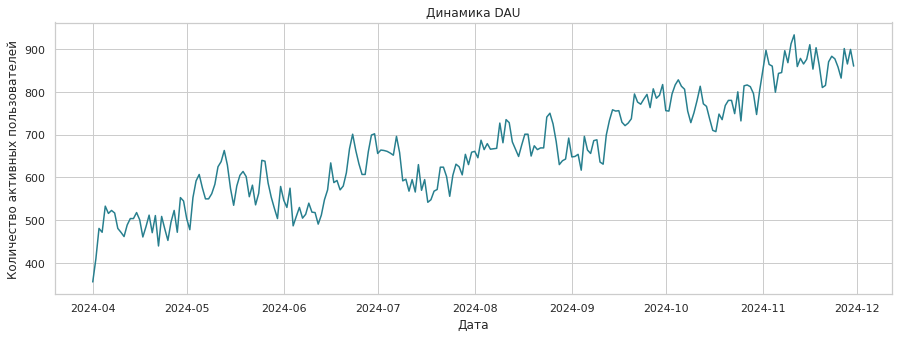

In [17]:
plt.figure(figsize=(15, 5))

sns.lineplot(
    data=daily_active_users,
    x='date',
    y='DAU',
    color=sns.color_palette('viridis') [2]
)

plt.title('Динамика DAU')
plt.xlabel('Дата')
plt.ylabel('Количество активных пользователей')

plt.show()

**Расчет MAU**

In [18]:
monthly_active_users = (
    df.groupby(df['session_start'].dt.to_period('M'))['user_id']
    .nunique()
    .reset_index()
)

monthly_active_users.columns = ['month', 'MAU']

monthly_active_users

,month,MAU
0,2024-04,9069
1,2024-05,10849
2,2024-06,10240
3,2024-07,10864
4,2024-08,11977
5,2024-09,12089
6,2024-10,13036
7,2024-11,14097


**Визуализация MAU**

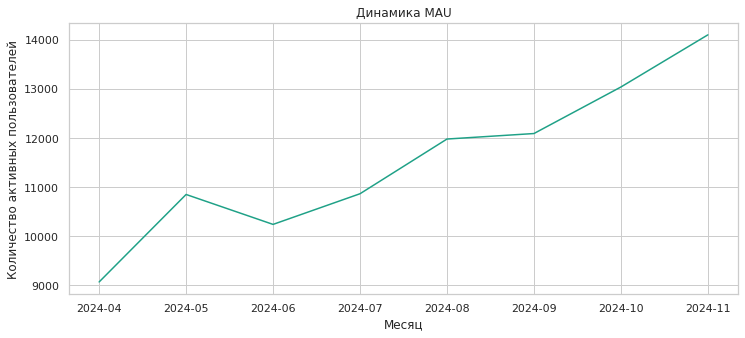

In [19]:
monthly_active_users['month'] = monthly_active_users['month'].astype(str)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_active_users,
    x='month',
    y='MAU',
    color=sns.color_palette('viridis')[3]
)

plt.title('Динамика MAU')
plt.xlabel('Месяц')
plt.ylabel('Количество активных пользователей')

plt.show()

**Расчет Stickiness**

In [20]:
daily_active_users['month'] = pd.to_datetime(
    daily_active_users['date']
).dt.to_period('M').astype(str)

monthly_dau = (
    daily_active_users
    .groupby('month')['DAU']
    .mean()
    .reset_index()
)

stickiness = monthly_dau.merge(
    monthly_active_users,
    on='month'
)

stickiness['Stickiness'] = (
    stickiness['DAU'] / stickiness['MAU'] * 100
)

stickiness

,month,DAU,MAU,Stickiness
0,2024-04,488.333333,9069,5.384644
1,2024-05,576.967742,10849,5.318165
2,2024-06,580.366667,10240,5.667643
3,2024-07,615.000000,10864,5.660898
4,2024-08,681.193548,11977,5.687514
5,2024-09,724.100000,12089,5.989743
6,2024-10,773.193548,13036,5.931218
7,2024-11,868.133333,14097,6.158284


**Визуализация Stickiness**

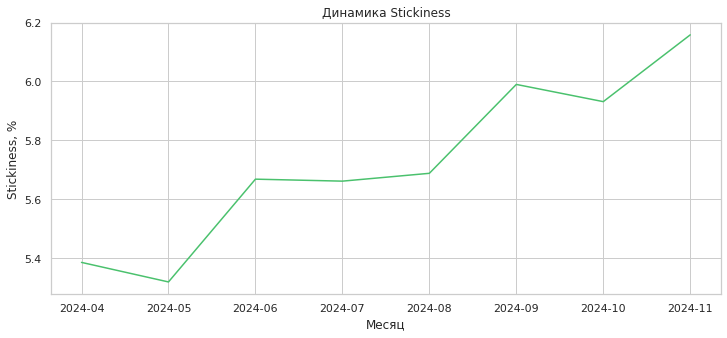

In [21]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=stickiness,
    x='month',
    y='Stickiness',
    color=sns.color_palette('viridis')[4]
)

plt.title('Динамика Stickiness')
plt.xlabel('Месяц')
plt.ylabel('Stickiness, %')

plt.show()

In [22]:
# Количество привлечённых пользователей по месяцам
monthly_users = (
    profiles
    .groupby(profiles['first_dt'].apply(lambda x: x.strftime('%Y-%m')))['user_id']
    .nunique()
    .reset_index(name='n_users')
)

monthly_users.columns = ['month', 'n_users']

# Расходы по месяцам
monthly_costs = (
    df_costs
    .groupby(df_costs['dt'].apply(lambda x: x.strftime('%Y-%m')))['costs']
    .sum()
    .reset_index()
)

monthly_costs.columns = ['month', 'costs']

# Расчет CAC
monthly_cac = monthly_costs.merge(
    monthly_users,
    on='month'
)

monthly_cac['CAC'] = (
    monthly_cac['costs'] / monthly_cac['n_users']
)

monthly_cac

,month,costs,n_users,CAC
0,2024-04,6663.052333,9069,0.734706
1,2024-05,7327.775412,9789,0.748572
2,2024-06,8492.116887,8719,0.973978
3,2024-07,9217.078561,8742,1.054344
4,2024-08,10999.013650,9518,1.155601
5,2024-09,10838.014747,9198,1.178301
6,2024-10,12595.403113,9520,1.323047


**Визуализация CAC**

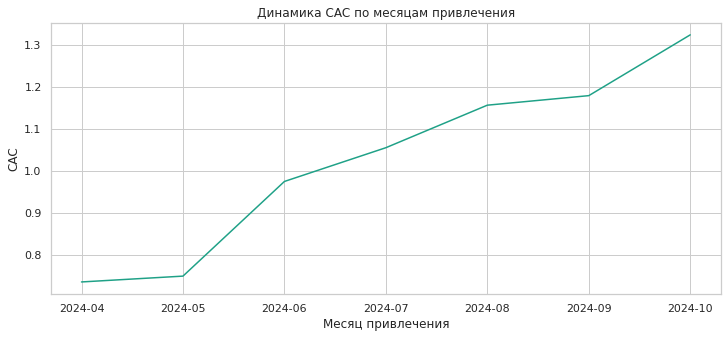

In [23]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_cac,
    x='month',
    y='CAC',
    color=sns.color_palette('viridis')[3]
)

plt.title('Динамика CAC по месяцам привлечения')
plt.xlabel('Месяц привлечения')
plt.ylabel('CAC')

plt.show()

**Расчет LTV**

In [24]:
orders_28d = df_orders[
    df_orders['lifetime'].between(0, 27)
].copy()
monthly_revenue = (
    orders_28d
    .groupby(orders_28d['first_dt'].apply(lambda x: x.strftime('%Y-%m')))['revenue']
    .sum()
    .reset_index()
)

monthly_revenue.columns = ['month', 'revenue']
monthly_ltv = monthly_revenue.merge(
    monthly_users,
    on='month'
)

monthly_ltv['LTV'] = (
    monthly_ltv['revenue'] / monthly_ltv['n_users']
)
monthly_ltv

,month,revenue,n_users,LTV
0,2024-04,7425.63,9069,0.818793
1,2024-05,8141.76,9789,0.831725
2,2024-06,7447.84,8719,0.854208
3,2024-07,9991.41,8742,1.142920
4,2024-08,10367.05,9518,1.089205
5,2024-09,10085.88,9198,1.096530
6,2024-10,11449.71,9520,1.202701


**Визуализация LTV**

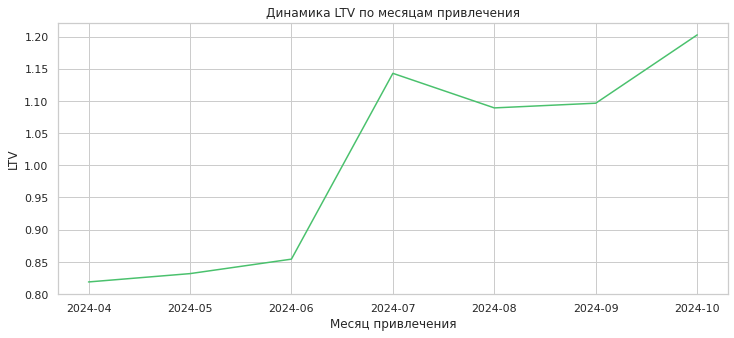

In [25]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_ltv,
    x='month',
    y='LTV',
    color=sns.color_palette('viridis')[4]
)

plt.title('Динамика LTV по месяцам привлечения')
plt.xlabel('Месяц привлечения')
plt.ylabel('LTV')

plt.show()

**Расчет ROI**

In [26]:
monthly_roi = monthly_ltv[['month', 'LTV']].merge(
    monthly_cac[['month', 'CAC']],
    on='month'
)

monthly_roi['ROI'] = (
    (monthly_roi['LTV'] - monthly_roi['CAC'])
    / monthly_roi['CAC']
    * 100
)
monthly_roi

,month,LTV,CAC,ROI
0,2024-04,0.818793,0.734706,11.444870
1,2024-05,0.831725,0.748572,11.108209
2,2024-06,0.854208,0.973978,-12.297015
3,2024-07,1.142920,1.054344,8.401051
4,2024-08,1.089205,1.155601,-5.745639
5,2024-09,1.096530,1.178301,-6.939783
6,2024-10,1.202701,1.323047,-9.096121


**Визуализация ROI**

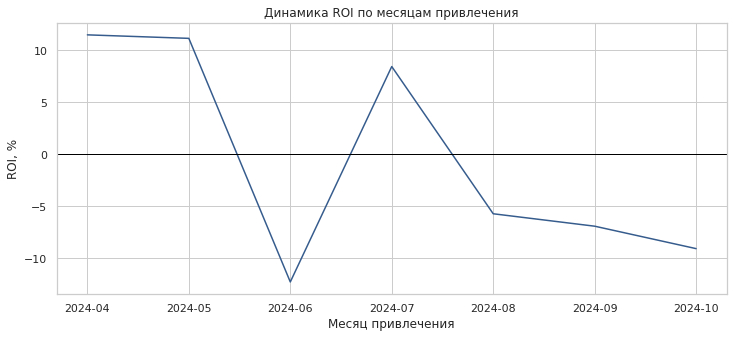

In [27]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_roi,
    x='month',
    y='ROI',
    color=sns.color_palette('viridis')[1]
)

plt.axhline(0, color='black', linewidth=1)

plt.title('Динамика ROI по месяцам привлечения')
plt.xlabel('Месяц привлечения')
plt.ylabel('ROI, %')

plt.show()

На графиках можно заметить устойчивый тренд на повышение **DAU**, **MAU** и **Stickness**. Скачков летом не было, поэтому сделать вывод о том, что на рост количества активных пользователей повлияла именно смена маркетинговой стратегии, сдедать нельзя. 

Можно заметить также и устойчивый рост **CAC**, на который летняя смена маркетинговой стратегии критично не повлияла, так как рост начался еще до лета. Зато на графике с **LTV** можно заметить, что смена маркетинговой стратегии положительно сказалась на этой метрике, можно заметить, что рост этой метрики усилился в июне. Однако, на графике с **ROI** можно заметить причину стагнации прибыли. Так как хотя в июне метрика стала больше 0, в июле она снова упала ниже значения окупаемости. 

Так происходит вероятно из-за того, что траты на привлечение пользователя увеличиваются слишком быстро. **CAC** растет быстрее **LTV**. 

## Анализ метрик по источникам привлечения

**Расчет количества пользователей по источникам привлечения**

In [28]:
users_by_source = (
    profiles
    .groupby('first_channel')['user_id']
    .nunique()
    .reset_index(name='n_users')
    .sort_values('n_users', ascending=False)
)
users_by_source

,first_channel,n_users
0,FaceBoom,24339
3,TipTop,15413
2,RocketSuperAds,12492
1,MediaTornado,12311


**Визуализация количества пользователей по источникам привлечения**

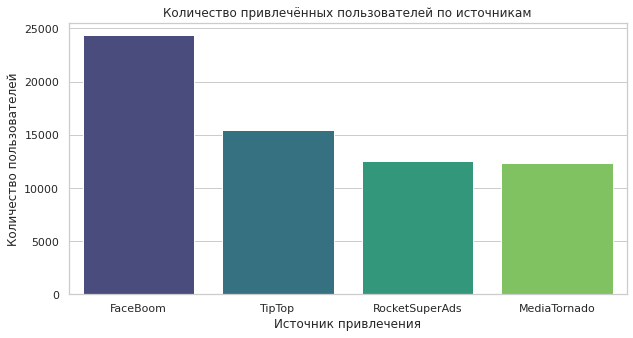

In [29]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=users_by_source,
    x='first_channel',
    y='n_users',
    palette='viridis'
)

plt.title('Количество привлечённых пользователей по источникам')
plt.xlabel('Источник привлечения')
plt.ylabel('Количество пользователей')

plt.show()

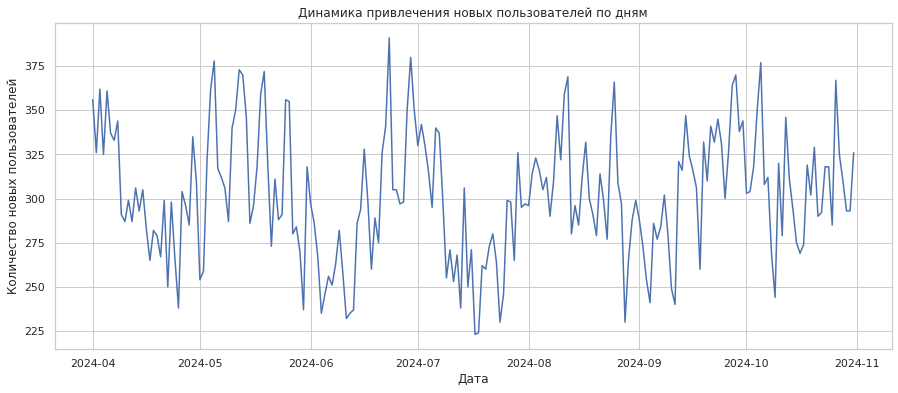

In [53]:
daily_new_users = (
    profiles
    .groupby('first_dt')['user_id']
    .nunique()
    .reset_index(name='new_users')
)

daily_new_users['first_dt'] = pd.to_datetime(daily_new_users['first_dt'])

plt.figure(figsize=(15, 6))

sns.lineplot(
    data=daily_new_users,
    x='first_dt',
    y='new_users'
)

plt.title('Динамика привлечения новых пользователей по дням')
plt.xlabel('Дата')
plt.ylabel('Количество новых пользователей')
plt.show()

**Расчет DAU по источникам привлечения**

In [30]:
daily_dau_by_source = (
    df.groupby([
        df['session_start'].dt.date,
        'first_channel'
    ])['user_id']
    .nunique()
    .reset_index()
)


daily_dau_by_source.columns = ['date', 'first_channel', 'DAU']

daily_dau_by_source['DAU_7d'] = (
    daily_dau_by_source
    .sort_values('date')
    .groupby('first_channel')['DAU']
    .transform(lambda x: x.rolling(7, min_periods=1).mean())
)

**Визуализация DAU по источникам привлечения**

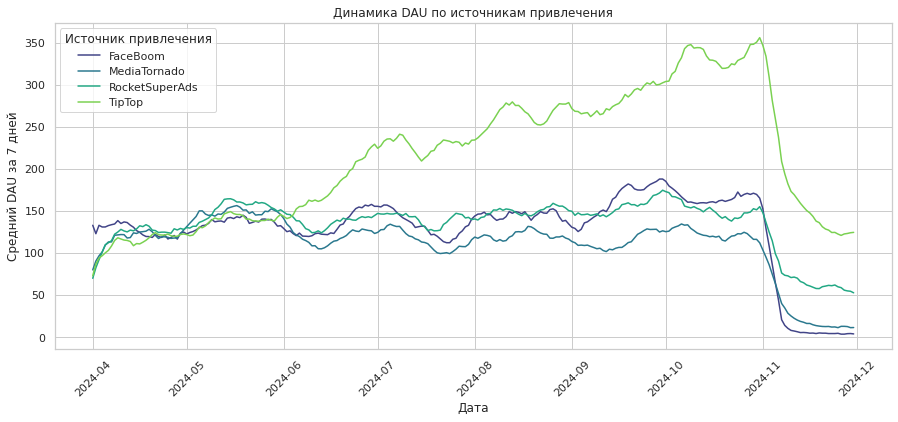

In [31]:
plt.figure(figsize=(15, 6))

sns.lineplot(
    data=daily_dau_by_source,
    x='date',
    y='DAU_7d',
    hue='first_channel',
    palette='viridis'
)

plt.title('Динамика DAU по источникам привлечения')
plt.xlabel('Дата')
plt.ylabel('Средний DAU за 7 дней')
plt.xticks(rotation=45)
plt.legend(title='Источник привлечения')

plt.show()

**Расчет MAU по источникам привлечения**

In [32]:
monthly_mau_by_source = (
    df.groupby([
        df['session_start'].dt.to_period('M'),
        'first_channel'
    ])['user_id']
    .nunique()
    .reset_index()
)

monthly_mau_by_source.columns = ['month', 'first_channel', 'MAU']

monthly_mau_by_source['month'] = (
    monthly_mau_by_source['month'].astype(str)
)


**Визуализация MAU по источникам привлечения**

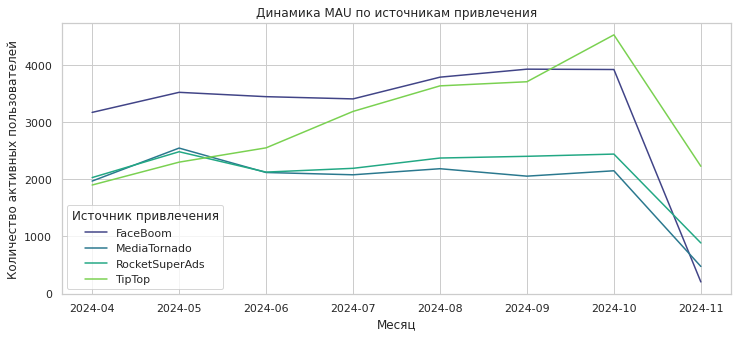

In [33]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_mau_by_source,
    x='month',
    y='MAU',
    hue='first_channel',
    palette='viridis'
)

plt.title('Динамика MAU по источникам привлечения')
plt.xlabel('Месяц')
plt.ylabel('Количество активных пользователей')
plt.legend(title='Источник привлечения')

plt.show()

**Расчет Stickness по источникам привлечения**

In [34]:
daily_dau_by_source['month'] = (
    pd.to_datetime(daily_dau_by_source['date'])
    .dt.to_period('M')
    .astype(str)
)

monthly_dau_by_source = (
    daily_dau_by_source
    .groupby(['month', 'first_channel'])['DAU']
    .mean()
    .reset_index()
)

stickiness_by_source = monthly_dau_by_source.merge(
    monthly_mau_by_source,
    on=['month', 'first_channel']
)

stickiness_by_source['Stickiness'] = (
    stickiness_by_source['DAU']
    / stickiness_by_source['MAU']
    * 100
)

stickiness_by_source.head()

,month,first_channel,DAU,MAU,Stickiness
0,2024-04,FaceBoom,126.433333,3170,3.988433
1,2024-04,MediaTornado,121.100000,1969,6.150330
2,2024-04,RocketSuperAds,124.600000,2030,6.137931
3,2024-04,TipTop,116.200000,1900,6.115789
4,2024-05,FaceBoom,135.774194,3521,3.856126


**Визуализация Stickness по источникам привлечения**

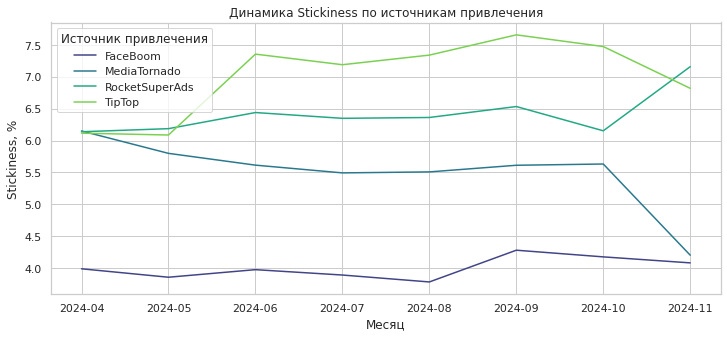

In [35]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=stickiness_by_source,
    x='month',
    y='Stickiness',
    hue='first_channel',
    palette='viridis'
)

plt.title('Динамика Stickiness по источникам привлечения')
plt.xlabel('Месяц')
plt.ylabel('Stickiness, %')
plt.legend(title='Источник привлечения')

plt.show()

Больше всего пользователей было привлечено из источника FaceBoom - 28401, из TipTop	- 18118, из RocketSuperAds - 14257, из MediaTornado	- 14080. При этом динамика DAU для FaceBoom, RocketSuperAds и MediaTornado практически не изменилась, оставшись на приблизительно одном уровне (с увеличением активности в начале месяца, спадом в конце, и общим небольшим трендом на увеличение). При этом DAU пользователей, привлеченных из TipTop показало резкий скачок в начале лета, из чего можно сделать вывод, что вероятно именно в этом источнике есть целевая аудитория спортивного контента. У TipTop также случился скачок MAU в июне. Также необходимо отметить, что у FaceBoom высокий MAU, и при этом из-за небольшого DAU очень низкий Stickiness (около 4%), что может говорить о маленькой вовлеченности пользователей, пришедших из данного источника. При этом у пользователей из других источников Stickiness стабильно держится на уровне от 5,5 до 7,5%. Общая динамика привлечения по дням показывает, что общие значения остались на том же уровне (ненадолго увеличилась, а потом вернулись к прежним колебаниям).

**Расчет скользящего удержания на 14-й день с момента привлечения (за период с 14-го по 28-й день)**

In [36]:
df['cohort_week'] = (
    pd.to_datetime(df['first_dt'])
    .dt.to_period('W')
    .apply(lambda x: x.start_time)
)

rolling_retention_users = (
    df[df['lifetime'].between(14, 27)]
    [['user_id', 'cohort_week', 'first_channel']]
    .drop_duplicates()
)

rolling_retention = (
    rolling_retention_users
    .groupby(['cohort_week', 'first_channel'])['user_id']
    .nunique()
    .reset_index(name='retained_users')
)

cohort_users = (
    profiles.assign(
        cohort_week=pd.to_datetime(profiles['first_dt'])
        .dt.to_period('W')
        .apply(lambda x: x.start_time)
    )
    .groupby(['cohort_week', 'first_channel'])['user_id']
    .nunique()
    .reset_index(name='cohort_users')
)

rolling_retention = rolling_retention.merge(
    cohort_users,
    on=['cohort_week', 'first_channel'],
    how='left'
)

rolling_retention['rolling_retention_14'] = (
    rolling_retention['retained_users']
    / rolling_retention['cohort_users']
    * 100
)


**Визуализация скользящего удержания на 14-й день с момента привлечения (за период с 14-го по 28-й день)**

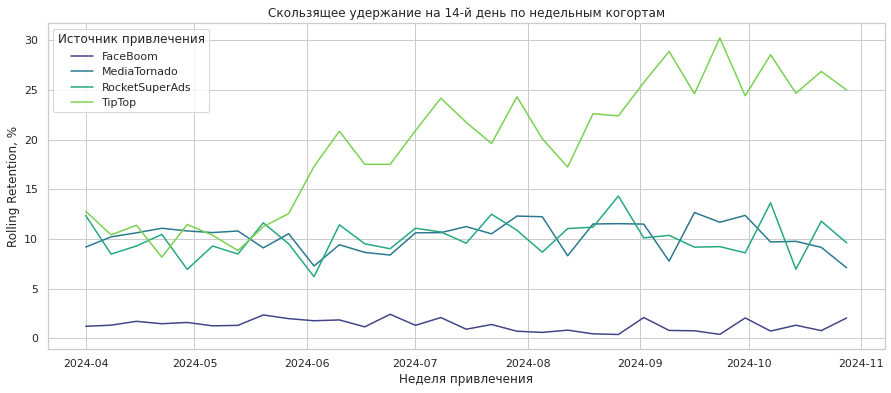

In [37]:
plt.figure(figsize=(15, 6))

sns.lineplot(
    data=rolling_retention,
    x='cohort_week',
    y='rolling_retention_14',
    hue='first_channel',
    palette='viridis'
)

plt.title('Скользящее удержание на 14-й день по недельным когортам')
plt.xlabel('Неделя привлечения')
plt.ylabel('Rolling Retention, %')
plt.legend(title='Источник привлечения')
plt.show()

**Расчет конверсии в покупку по недельным когортам**

In [38]:
buyers_28d = (
    df_orders[df_orders['lifetime'].between(0, 27)]
    [['user_id', 'first_dt', 'first_channel']]
    .drop_duplicates()
)

buyers_28d['cohort_week'] = (
    pd.to_datetime(buyers_28d['first_dt'])
    .dt.to_period('W')
    .apply(lambda x: x.start_time)
)

conversion = (
    buyers_28d
    .groupby(['cohort_week', 'first_channel'])['user_id']
    .nunique()
    .reset_index(name='buyers')
)

conversion = conversion.merge(
    cohort_users,
    on=['cohort_week', 'first_channel'],
    how='left'
)

conversion['conversion'] = (
    conversion['buyers']
    / conversion['cohort_users']
    * 100
)

**Визуализация конверсии в покупку по недельным когортам**

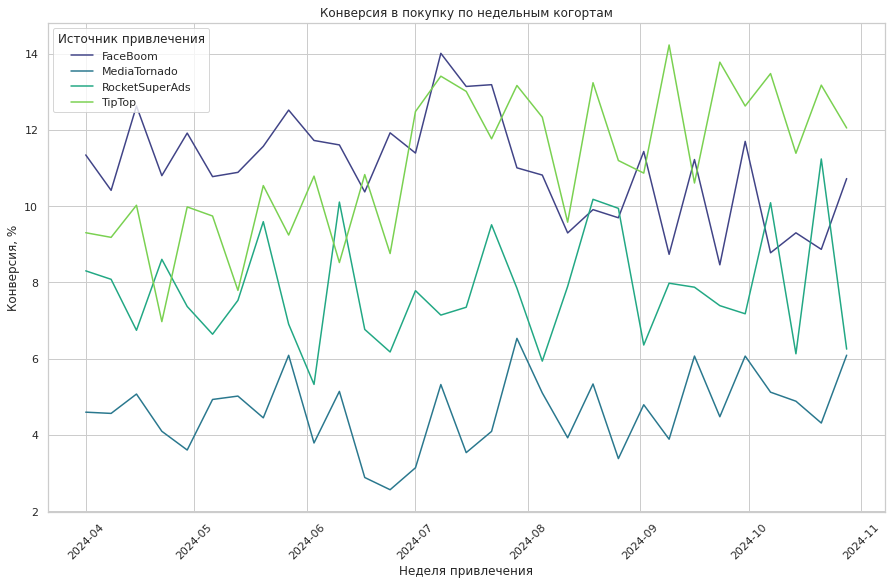

In [39]:
conversion['cohort_week'] = (
    conversion['cohort_week']
)

plt.figure(figsize=(15, 9))

sns.lineplot(
    data=conversion,
    x='cohort_week',
    y='conversion',
    hue='first_channel',
    palette='viridis'
)

plt.title('Конверсия в покупку по недельным когортам')
plt.xlabel('Неделя привлечения')
plt.ylabel('Конверсия, %')
plt.xticks(rotation=45)
plt.legend(title='Источник привлечения')
plt.show()

**Расчет недельной динамики затрат на маркетинг по каждому источнику**

In [40]:
df_costs['week'] = (
    pd.to_datetime(df_costs['dt'])
    .dt.to_period('W')
    .apply(lambda x: x.start_time)
)

weekly_costs = (
    df_costs
    .groupby(['week', 'channel'])['costs']
    .sum()
    .reset_index()
)

**Визуализация недельной динамики затрат на маркетинг по каждому источнику**

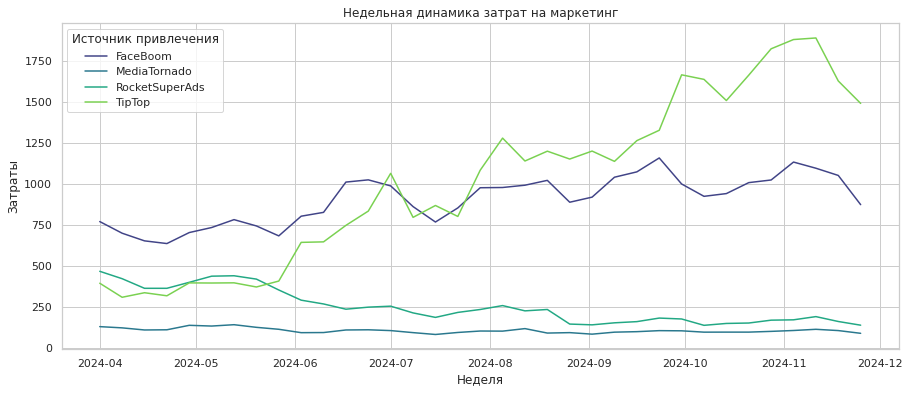

In [41]:
plt.figure(figsize=(15, 6))

sns.lineplot(
    data=weekly_costs,
    x='week',
    y='costs',
    hue='channel',
    palette='viridis'
)

plt.title('Недельная динамика затрат на маркетинг')
plt.xlabel('Неделя')
plt.ylabel('Затраты')
plt.legend(title='Источник привлечения')
plt.show()

**Расчет недельной динамики CAC**

In [42]:
weekly_users = (
    profiles.assign(
        week=pd.to_datetime(profiles['first_dt'])
        .dt.to_period('W')
        .apply(lambda x: x.start_time)
    )
    .groupby(['week', 'first_channel'])['user_id']
    .nunique()
    .reset_index(name='n_users')
)

weekly_costs = (
    df_costs.assign(
        week=pd.to_datetime(df_costs['dt'])
        .dt.to_period('W')
        .apply(lambda x: x.start_time)
    )
    .groupby(['week', 'channel'])['costs']
    .sum()
    .reset_index()
    .rename(columns={'channel': 'first_channel'})
)

weekly_cac = weekly_costs.merge(
    weekly_users,
    on=['week', 'first_channel'],
    how='left'
)

weekly_cac['CAC'] = (
    weekly_cac['costs']
    / weekly_cac['n_users']
)

**Визуализация недельной динамики CAC**

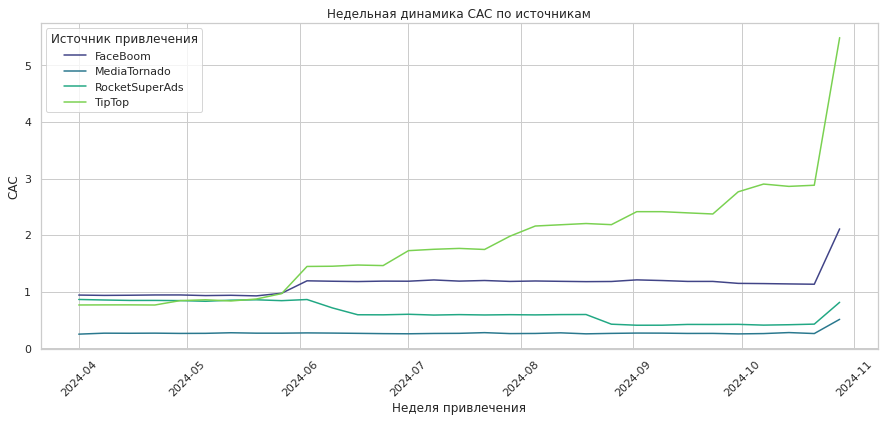

In [43]:
plt.figure(figsize=(15, 6))

sns.lineplot(
    data=weekly_cac,
    x='week',
    y='CAC',
    hue='first_channel',
    palette='viridis'
)

plt.title('Недельная динамика CAC по источникам')
plt.xlabel('Неделя привлечения')
plt.ylabel('CAC')
plt.xticks(rotation=45)
plt.legend(title='Источник привлечения')
plt.show()

**Расчет недельной динамики LTV**

In [44]:
weekly_revenue = (
    df_orders[df_orders['lifetime'].between(0, 27)]
    .assign(
        week=pd.to_datetime(df_orders.loc[
            df_orders['lifetime'].between(0, 27), 'first_dt'
        ])
        .dt.to_period('W')
        .apply(lambda x: x.start_time)
    )
    .groupby(['week', 'first_channel'])['revenue']
    .sum()
    .reset_index()
)

weekly_ltv = weekly_revenue.merge(
    weekly_users,
    on=['week', 'first_channel'],
    how='right'
)

weekly_ltv['revenue'] = weekly_ltv['revenue'].fillna(0)

weekly_ltv['LTV'] = (
    weekly_ltv['revenue']
    / weekly_ltv['n_users']
)

**Визуализация недельной динамики LTV**

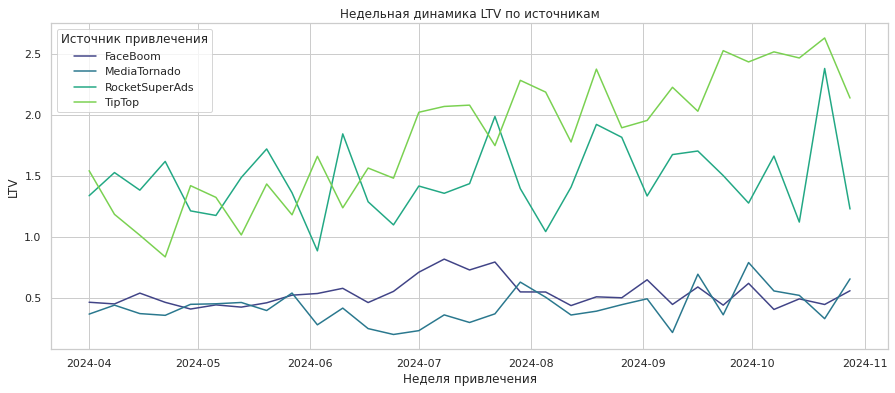

In [45]:
plt.figure(figsize=(15, 6))

sns.lineplot(
    data=weekly_ltv,
    x='week',
    y='LTV',
    hue='first_channel',
    palette='viridis'
)

plt.title('Недельная динамика LTV по источникам')
plt.xlabel('Неделя привлечения')
plt.ylabel('LTV')
plt.legend(title='Источник привлечения')
plt.show()

**Расчет недельной динамики ROI**

In [46]:
weekly_roi = weekly_ltv[['week', 'first_channel', 'LTV']].merge(
    weekly_cac[['week', 'first_channel', 'CAC']],
    on=['week', 'first_channel'],
    how='left'
)

weekly_roi['ROI'] = (
    (weekly_roi['LTV'] - weekly_roi['CAC'])
    / weekly_roi['CAC']
    * 100
)

**Визуализация недельной динамики ROI**

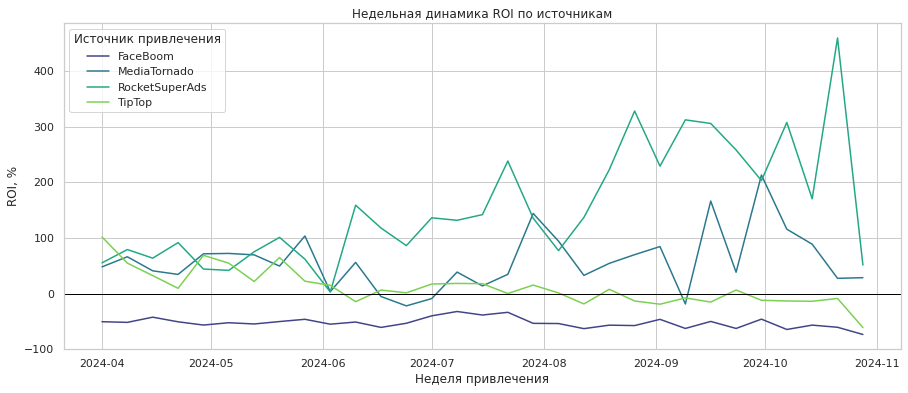

In [47]:
plt.figure(figsize=(15, 6))

sns.lineplot(
    data=weekly_roi,
    x='week',
    y='ROI',
    hue='first_channel',
    palette='viridis'
)

plt.axhline(0, color='black', linewidth=1)

plt.title('Недельная динамика ROI по источникам')
plt.xlabel('Неделя привлечения')
plt.ylabel('ROI, %')
plt.legend(title='Источник привлечения')
plt.show()

Уже можно сделать вывод, что **RocketSuperAds** демонстрирует лучшие показатели, так как это единственный источник, каждая когорта которого вышла на окупаемость в запланированный период, при этом остальные показатели этого источника также удовлетворительные. Также можно заметить, что самый массовый источник, привлекший больше всего пользователей - **FaceBoom**, имеет плохое удержание пользователей, конверсия в покупку у данных пользователей начала заметно падать. Из-за низкого удержания пользователя, также возникают проблемы с окупаемостью затрат на привлечение. При том, что у **TipTop** растущее высокое удержание, высокая растущая конверсия, затраты на привлечение пользователя растут ещё сильнее, из-за чего исчезает окупаемость в запланированный период. **MediaTornado** имеет средние показатели, низкую конверсию в покупку, зато ROI опускается ниже нуля лишь у нескольких когорт.  

## Анализ периода окупаемости маркетинговых вложений

**Тепловая карта ROI за 9 недель для источника FaceBoom**

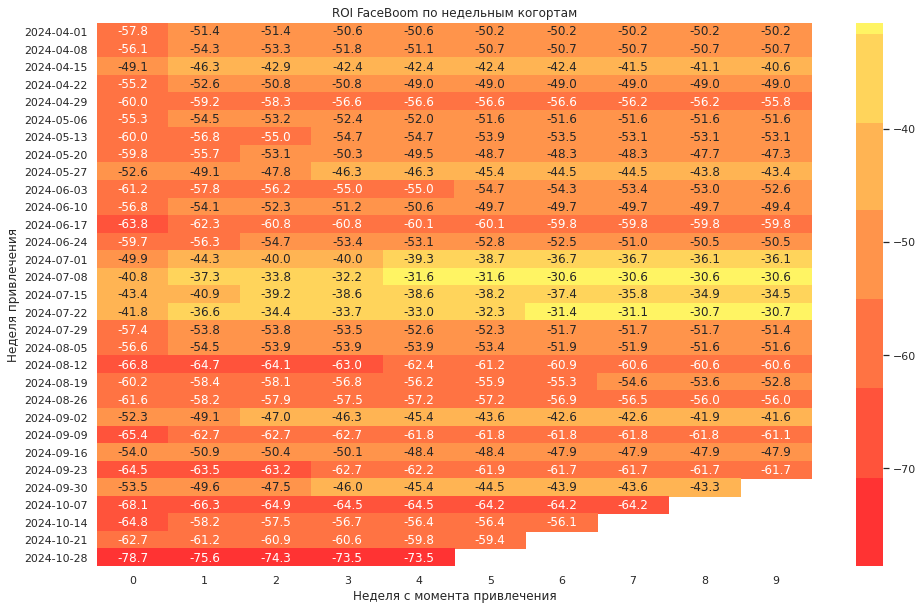

In [48]:
faceboom_orders = df_orders[
    (df_orders['first_channel'] == 'FaceBoom') &
    (df_orders['lifetime'].between(0, 69))
].copy()

faceboom_orders['cohort_week'] = (
    pd.to_datetime(faceboom_orders['first_dt'])
    .dt.to_period('W')
    .apply(lambda x: x.start_time)
)

faceboom_orders['lifetime_week'] = (
    faceboom_orders['lifetime'] // 7
)

weekly_revenue = (
    faceboom_orders
    .groupby([
        'cohort_week',
        'lifetime_week'
    ])['revenue']
    .sum()
    .reset_index()
)

cohort_weeks = (
    profiles[
        profiles['first_channel'] == 'FaceBoom'
    ]
    .assign(
        cohort_week=lambda x: pd.to_datetime(x['first_dt'])
        .dt.to_period('W')
        .apply(lambda x: x.start_time)
    )['cohort_week']
    .drop_duplicates()
    .sort_values()
)

all_periods = []

max_lifetime_week = 9

for cohort in cohort_weeks:
    
    available_weeks = min(
        max_lifetime_week,
        (pd.to_datetime(df_orders['event_dt'].max()).date()
         - cohort.date()).days // 7
    )
    
    for lifetime_week in range(available_weeks + 1):
        all_periods.append([
            cohort,
            lifetime_week
        ])


all_periods = pd.DataFrame(
    all_periods,
    columns=['cohort_week', 'lifetime_week']
)

faceboom_revenue = all_periods.merge(
    weekly_revenue,
    on=['cohort_week', 'lifetime_week'],
    how='left'
)


faceboom_revenue['revenue'] = (
    faceboom_revenue['revenue']
    .fillna(0)
)

faceboom_revenue = (
    faceboom_revenue
    .sort_values([
        'cohort_week',
        'lifetime_week'
    ])
)

faceboom_revenue['revenue_cumulative'] = (
    faceboom_revenue
    .groupby('cohort_week')['revenue']
    .cumsum()
)

faceboom_users = (
    profiles[
        profiles['first_channel'] == 'FaceBoom'
    ]
    .assign(
        cohort_week=lambda x: pd.to_datetime(x['first_dt'])
        .dt.to_period('W')
        .apply(lambda x: x.start_time)
    )
    .groupby('cohort_week')['user_id']
    .nunique()
    .reset_index(name='n_users')
)

faceboom_costs = (
    df_costs[
        df_costs['channel'] == 'FaceBoom'
    ]
    .assign(
        cohort_week=lambda x: pd.to_datetime(x['dt'])
        .dt.to_period('W')
        .apply(lambda x: x.start_time)
    )
    .groupby('cohort_week')['costs']
    .sum()
    .reset_index()
)

faceboom_roi = faceboom_revenue.merge(
    faceboom_users,
    on='cohort_week',
    how='left'
)

faceboom_roi = faceboom_roi.merge(
    faceboom_costs,
    on='cohort_week',
    how='left'
)

faceboom_roi['CAC'] = (
    faceboom_roi['costs']
    / faceboom_roi['n_users']
)

faceboom_roi['LTV'] = (
    faceboom_roi['revenue_cumulative']
    / faceboom_roi['n_users']
)

faceboom_roi['ROI'] = (
    (faceboom_roi['LTV'] - faceboom_roi['CAC'])
    / faceboom_roi['CAC']
    * 100
)

roi_faceboom_pivot = faceboom_roi.pivot(
    index='cohort_week',
    columns='lifetime_week',
    values='ROI'
)

roi_faceboom_pivot.index = roi_faceboom_pivot.index.date

cmap = mcolors.LinearSegmentedColormap.from_list(
    'green_red',
    ['#FF3333', '#FFFF66', '#4C9900', '#006600'],
    N=20
)

plt.figure(figsize=(16, 10))

sns.heatmap(
    roi_faceboom_pivot,
    annot=True,
    fmt='.1f',
    cmap=cmap,
    center=0
)

plt.title('ROI FaceBoom по недельным когортам')
plt.xlabel('Неделя с момента привлечения')
plt.ylabel('Неделя привлечения')

plt.show()

**Тепловая карта ROI за 9 недель для источника TipTop**

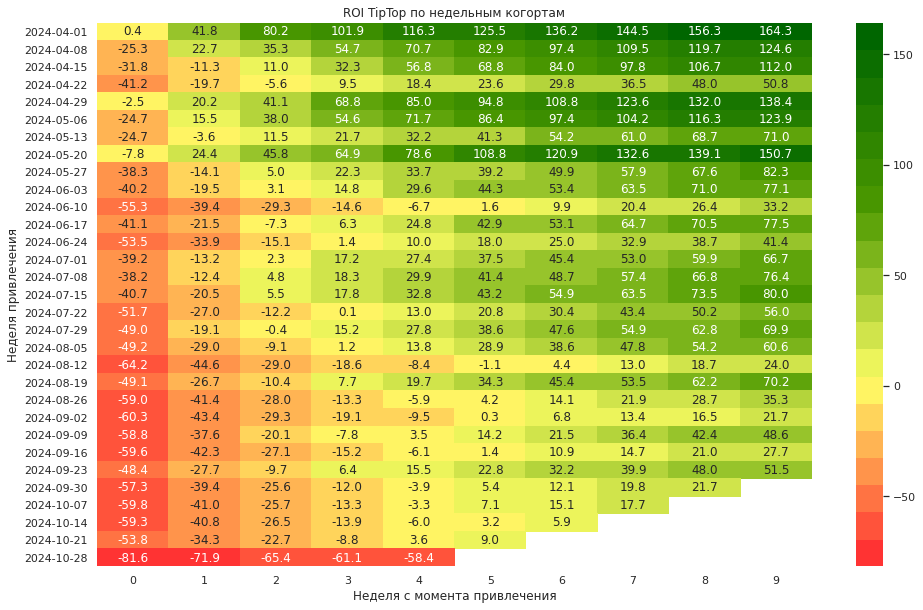

In [49]:
tiptop_orders = df_orders[
    (df_orders['first_channel'] == 'TipTop') &
    (df_orders['lifetime'].between(0, 69))
].copy()

tiptop_orders['cohort_week'] = (
    pd.to_datetime(tiptop_orders['first_dt'])
    .dt.to_period('W')
    .apply(lambda x: x.start_time)
)

tiptop_orders['lifetime_week'] = (
    tiptop_orders['lifetime'] // 7
)

weekly_revenue = (
    tiptop_orders
    .groupby([
        'cohort_week',
        'lifetime_week'
    ])['revenue']
    .sum()
    .reset_index()
)

cohort_weeks = (
    profiles[
        profiles['first_channel'] == 'TipTop'
    ]
    .assign(
        cohort_week=lambda x: pd.to_datetime(x['first_dt'])
        .dt.to_period('W')
        .apply(lambda x: x.start_time)
    )['cohort_week']
    .drop_duplicates()
    .sort_values()
)

all_periods = []

max_lifetime_week = 9

for cohort in cohort_weeks:
    
    available_weeks = min(
        max_lifetime_week,
        (pd.to_datetime(df_orders['event_dt'].max()).date()
         - cohort.date()).days // 7
    )
    
    for lifetime_week in range(available_weeks + 1):
        all_periods.append([
            cohort,
            lifetime_week
        ])


all_periods = pd.DataFrame(
    all_periods,
    columns=['cohort_week', 'lifetime_week']
)

tiptop_revenue = all_periods.merge(
    weekly_revenue,
    on=['cohort_week', 'lifetime_week'],
    how='left'
)

tiptop_revenue['revenue'] = (
    tiptop_revenue['revenue']
    .fillna(0)
)

tiptop_revenue = (
    tiptop_revenue
    .sort_values([
        'cohort_week',
        'lifetime_week'
    ])
)

tiptop_revenue['revenue_cumulative'] = (
    tiptop_revenue
    .groupby('cohort_week')['revenue']
    .cumsum()
)

tiptop_users = (
    profiles[
        profiles['first_channel'] == 'TipTop'
    ]
    .assign(
        cohort_week=lambda x: pd.to_datetime(x['first_dt'])
        .dt.to_period('W')
        .apply(lambda x: x.start_time)
    )
    .groupby('cohort_week')['user_id']
    .nunique()
    .reset_index(name='n_users')
)

tiptop_costs = (
    df_costs[
        df_costs['channel'] == 'TipTop'
    ]
    .assign(
        cohort_week=lambda x: pd.to_datetime(x['dt'])
        .dt.to_period('W')
        .apply(lambda x: x.start_time)
    )
    .groupby('cohort_week')['costs']
    .sum()
    .reset_index()
)

tiptop_roi = tiptop_revenue.merge(
    tiptop_users,
    on='cohort_week',
    how='left'
)

tiptop_roi = tiptop_roi.merge(
    tiptop_costs,
    on='cohort_week',
    how='left'
)

tiptop_roi['CAC'] = (
    tiptop_roi['costs']
    / tiptop_roi['n_users']
)

tiptop_roi['LTV'] = (
    tiptop_roi['revenue_cumulative']
    / tiptop_roi['n_users']
)

tiptop_roi['ROI'] = (
    (tiptop_roi['LTV'] - tiptop_roi['CAC'])
    / tiptop_roi['CAC']
    * 100
)

roi_tiptop_pivot = tiptop_roi.pivot(
    index='cohort_week',
    columns='lifetime_week',
    values='ROI'
)

roi_tiptop_pivot.index = (
    roi_tiptop_pivot.index.date
)

plt.figure(figsize=(16, 10))

sns.heatmap(
    roi_tiptop_pivot,
    annot=True,
    fmt='.1f',
    cmap=cmap
)

plt.title('ROI TipTop по недельным когортам')
plt.xlabel('Неделя с момента привлечения')
plt.ylabel('Неделя привлечения')

plt.show()

**Тепловая карта ROI за 9 недель для источника MediaTornado**

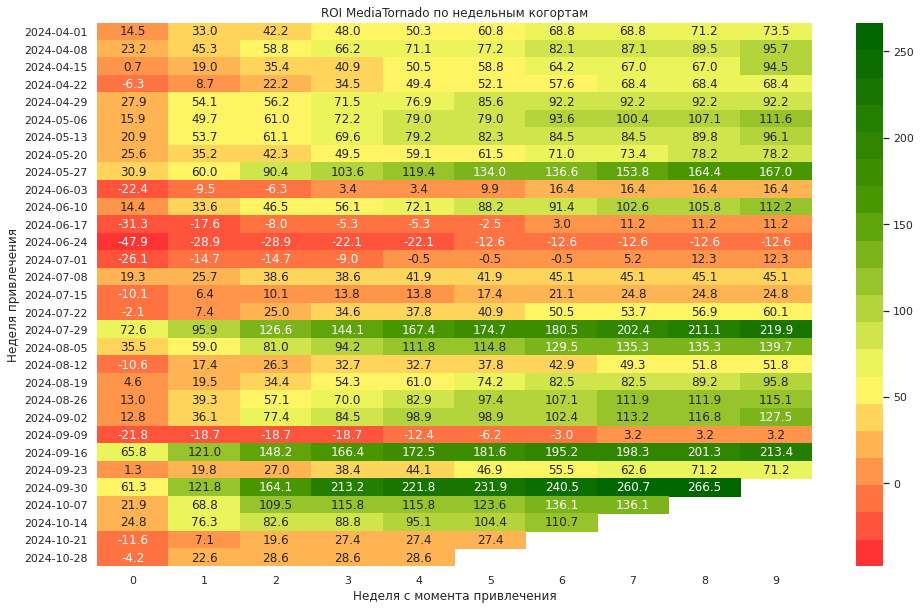

In [50]:
media_tornado_orders = df_orders[
    (df_orders['first_channel'] == 'MediaTornado') &
    (df_orders['lifetime'].between(0, 69))
].copy()

media_tornado_orders['cohort_week'] = (
    pd.to_datetime(media_tornado_orders['first_dt'])
    .dt.to_period('W')
    .apply(lambda x: x.start_time)
)

media_tornado_orders['lifetime_week'] = (
    media_tornado_orders['lifetime'] // 7
)

weekly_revenue = (
    media_tornado_orders
    .groupby([
        'cohort_week',
        'lifetime_week'
    ])['revenue']
    .sum()
    .reset_index()
)

cohort_weeks = (
    profiles[
        profiles['first_channel'] == 'MediaTornado'
    ]
    .assign(
        cohort_week=lambda x: pd.to_datetime(x['first_dt'])
        .dt.to_period('W')
        .apply(lambda x: x.start_time)
    )['cohort_week']
    .drop_duplicates()
    .sort_values()
)

all_periods = []

max_lifetime_week = 9

for cohort in cohort_weeks:
    
    available_weeks = min(
        max_lifetime_week,
        (pd.to_datetime(df_orders['event_dt'].max()).date()
         - cohort.date()).days // 7
    )
    
    for lifetime_week in range(available_weeks + 1):
        all_periods.append([
            cohort,
            lifetime_week
        ])


all_periods = pd.DataFrame(
    all_periods,
    columns=['cohort_week', 'lifetime_week']
)

media_tornado_revenue = all_periods.merge(
    weekly_revenue,
    on=['cohort_week', 'lifetime_week'],
    how='left'
)

media_tornado_revenue['revenue'] = (
    media_tornado_revenue['revenue']
    .fillna(0)
)

media_tornado_revenue = (
    media_tornado_revenue
    .sort_values([
        'cohort_week',
        'lifetime_week'
    ])
)

media_tornado_revenue['revenue_cumulative'] = (
    media_tornado_revenue
    .groupby('cohort_week')['revenue']
    .cumsum()
)

media_tornado_users = (
    profiles[
        profiles['first_channel'] == 'MediaTornado'
    ]
    .assign(
        cohort_week=lambda x: pd.to_datetime(x['first_dt'])
        .dt.to_period('W')
        .apply(lambda x: x.start_time)
    )
    .groupby('cohort_week')['user_id']
    .nunique()
    .reset_index(name='n_users')
)

media_tornado_costs = (
    df_costs[
        df_costs['channel'] == 'MediaTornado'
    ]
    .assign(
        cohort_week=lambda x: pd.to_datetime(x['dt'])
        .dt.to_period('W')
        .apply(lambda x: x.start_time)
    )
    .groupby('cohort_week')['costs']
    .sum()
    .reset_index()
)

media_tornado_roi = media_tornado_revenue.merge(
    media_tornado_users,
    on='cohort_week',
    how='left'
)

media_tornado_roi = media_tornado_roi.merge(
    media_tornado_costs,
    on='cohort_week',
    how='left'
)

media_tornado_roi['CAC'] = (
    media_tornado_roi['costs']
    / media_tornado_roi['n_users']
)

media_tornado_roi['LTV'] = (
    media_tornado_roi['revenue_cumulative']
    / media_tornado_roi['n_users']
)

media_tornado_roi['ROI'] = (
    (media_tornado_roi['LTV'] - media_tornado_roi['CAC'])
    / media_tornado_roi['CAC']
    * 100
)

roi_media_tornado_pivot = media_tornado_roi.pivot(
    index='cohort_week',
    columns='lifetime_week',
    values='ROI'
)


roi_media_tornado_pivot.index = (
    roi_media_tornado_pivot.index.date
)

plt.figure(figsize=(16, 10))

sns.heatmap(
    roi_media_tornado_pivot,
    annot=True,
    fmt='.1f',
    cmap=cmap
)

plt.title('ROI MediaTornado по недельным когортам')
plt.xlabel('Неделя с момента привлечения')
plt.ylabel('Неделя привлечения')

plt.show()

Источник **FaceBoom** не выходит на окупаемость даже в расширенный период. Источнику **TipTop** окупается в 3 раза медленнее целевого показателя - за 6 недель вместо запланированных 28 дней. А вот для **MediaTornado** в среднем окупаемость близка к целевым 28 дням, однако существует несколько аномальных когорт, которые не вышли на окупаемость даже за период в 9 недель. Например, когорта 09.09, которая имеет очень низкий показатель ROI даже на девятую неделю, соседствует с когортами с показателями 127,5% и 213,4%. Также можно отметить негативную реакцию когорт в начале лета, пришедших как раз во время нововведений. 

## Выводы и рекомендации

Сводная таблица сравнения показателей для пользователей, привлеченных из различных источников:

|  | Удержание | Конверсия в покупку | Затраты на маркетинг | CAC | LTV | ROI |
| :--- | :---: |:---: |:---: |:---: |:---: | ---: |
| FaceBoom | низкое | высокая (снижается) | средние | средний | 0,45 - 0,75 | не окупается за предусмотренный период |
| TipTop | высокое (выросло в июне) | высокая (растет) | высокие (сильно выросли) | высокий, сильный рост | 0,9 - 2,6 | не каждая когорта окупается за предусмотренный период, ROI падает |
| RocketSuperAds | среднее | средняя | низкие | низкий (снижается) | 0,9 - 2,4 | окупается за предусмотренный период |
| MediaTornado | среднее | низкая | низкие | низкий | 0,3 - 0,75 | не каждая когорта окупается за предусмотренный период |

Рекомендации: 

Первое, что стоит сделать для отмены стагнации выручки - снизить, желательно до нуля, затраты на привлечение пользователей из **FaceBoom**, так как потраченные на их привлечение ресурсы не окупаются, из-за того, что пользователи оттуда плохо удерживаются и стали совершать меньшее количество покупок.

Стоит внимательнее отнестись к маркетинговым тратам на **TipTop**, из данного источника привлекается целевая аудитори продукта (вовлеченная и платежеспособная), однако постоянно растущие затраты на привлечение ползователей, съедают весь доход. 

**MediaTornado** является неплохим источником, однако возможно в данном источнике нет целевой аудитории не конкретно приложения, а конкретно спорта, на который были направлены маркетинговые изменения летом. Также стоит рассмотреть, не вносились ли какие-то изменения или не присутствовали ли какие-то технические проблемы в неделю с 09.09.2024. Дабы в дальнейшем избежать аномальных не окупаемых когорт.

Лучшим источником оказался **RocketSuperAds**. Затраты на рекламу в нём стабильно окупаются. Пусть аудитория там не самая активная, менее подходящая, чем из TipTop, зато она стабильно удерживается и совершает покупки, а также не требует больших затрат на привлечение одного пользователя. 

Также необходимо отметить, что маркетинговые летние изменения практически не повлияли на **MediaTornado** и **RocketSuperAds**. Поэтому стоит либо рассмотреть возможности снизить маркетинговые затраты на  **TipTop** с сохранением трафика оттуда, либо рассмотреть модель с более длительной окупаемостью, либо рассмотреть другие направления, кроме спортивного, для дальнейшего продвижения приложения. 